# 3. Stored results discovery and analysis

This notebook reads metadata and saved arrays. It never performs propagation or Fourier fitting.

In [71]:
from pathlib import Path
import sys
import pandas as pd

# Locate the checkout so notebooks work without an editable install.
# Supported working directories: repository root or a directory inside it.
_here = Path.cwd().resolve()
ROOT = next(
    (directory for directory in (_here, *_here.parents)
     if (directory / "src" / "bosonic_algo" / "__init__.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError(
        "Cannot locate the bosonic_algo checkout from the notebook kernel's "
        "working directory. Start Jupyter in the repository root or its "
        "notebooks/ folder (or change the kernel working directory). "
        "For another environment, install from the repository root with "
        "'python -m pip install -e .'."
    )
_src = str(ROOT / "src")
if _src not in sys.path:
    sys.path.insert(0, _src)

FIT_ROOT = ROOT / "data" / "fits"
RESULT_ROOT = ROOT / "results"

from bosonic_algo import ResultStore
store = ResultStore(ROOT / "results")
metadata = store.list_results()
pd.DataFrame([{"run_id":m["run_id"], "method":m["method"], "fit_id":m["inputs"].get("fit_id"), "potential":m["inputs"].get("potential"), "cavity":m["inputs"]["config"]["cavity"]["enabled"], "created":m["created_utc"]} for m in metadata])

,run_id,method,fit_id,potential,cavity,created
0,8c17be205b5f17818a18,classical,fit_342a4798415698a4,fitted,False,2026-11-18T22:29:00.967810+00:00
1,b62c3150e6d9830adae2,classical,fit_f33d5a618d552ac9,fitted,False,2026-11-18T21:29:09.833791+00:00
2,e489ff4881f170922ea9,classical,NaN,exact,False,2026-11-18T21:26:53.736535+00:00


## Search a subset

Use `fit_id=...`, `include_cavity=...`, or `**{"config.tgifs.substeps": 20}` to filter metadata.

In [72]:
#matches = store.find_results(method="classical")
#[(m["run_id"], m["inputs"].get("fit_id")) for m in matches]

matches = store.find_results(method="classical")
[(m["method"], m["run_id"]) for m in matches]

[('classical', '8c17be205b5f17818a18'),
 ('classical', 'b62c3150e6d9830adae2'),
 ('classical', 'e489ff4881f170922ea9')]

## Retrieve and plot any saved run

Set an existing run ID and method from the table above; no simulation is performed.

Text(0.5, 0, 'time (fs)')

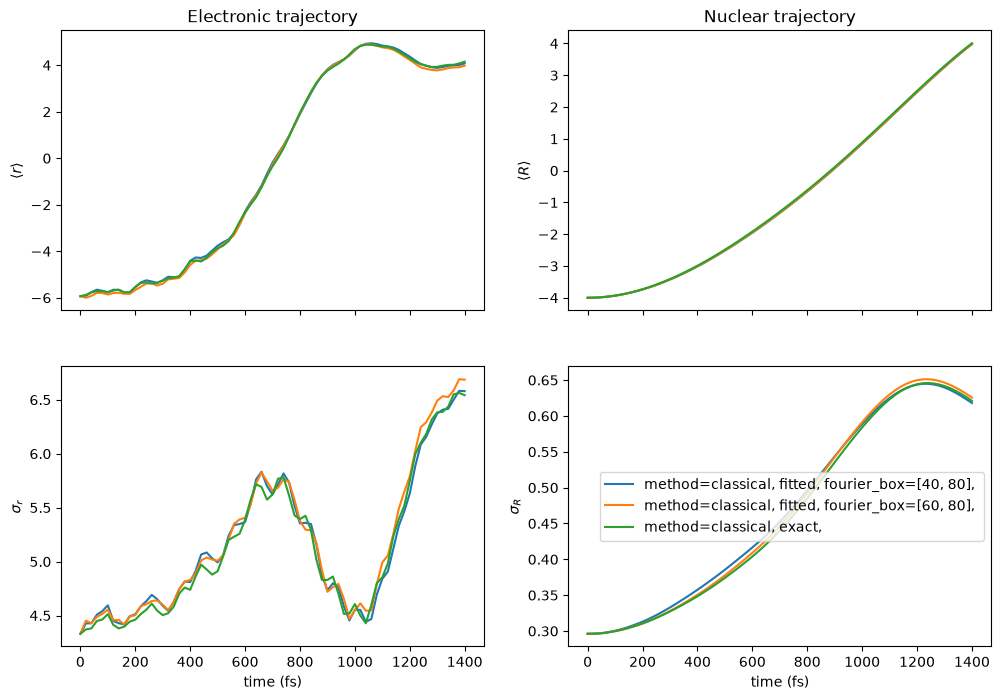

In [74]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)

panels = [
    ('mean_r', r'$\langle r\rangle$', axes[0,0]),
    ('mean_R', r'$\langle R\rangle$', axes[0,1]),
    ('sigma_r', r'$\sigma_r$', axes[1,0]),
    ('sigma_R', r'$\sigma_R$', axes[1,1]),
]

lab_keys_run = ['method']
lab_keys_fit = ['fourier_box']

for m in matches:
    METHOD, RUN_ID = (m["method"], m["run_id"])
    data, meta = store.load(METHOD, RUN_ID)
    #print(meta["inputs"])
    fit_id = meta["inputs"].get("fit_id")
    potential = meta["inputs"].get("potential")
    if potential == 'fitted':
        fit = load_fit(fit_id, FIT_ROOT)
        fit_meta = fit.metadata
      
    for key,label,ax in panels:
        lab = ''
        for k in lab_keys_run:
            lab = lab + k + "=" + str(meta[k]) + ", "
        lab = lab + potential + ", "
        if potential == 'fitted':
            for k in lab_keys_fit:
                lab = lab + k + "=" + str(fit_meta[k]) + ", "
        ax.plot(data["times"], data[key], '-',label = lab)
        ax.set_ylabel(label)
    

plt.legend()
axes[0,0].set_title('Electronic trajectory')
axes[0,1].set_title('Nuclear trajectory')
axes[1,0].set_xlabel('time (fs)')
axes[1,1].set_xlabel('time (fs)')